Разведочный анализ данных

Анализ исходных файлов организаторов и подготовленного датасета. Пути передаются
явно командой `python -m analysis.execute`; соседние рабочие папки не подставляются.
Контрольные суммы проверяются до расчётов. Таблицы и графики пересчитываются
при выполнении notebook, исходные карточки и имена продавцов не выводятся.

In [1]:
import json
import os
from datetime import UTC, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
from analysis.grounding import grounding
from analysis.overview import input_table, text_quality, traffic, verify_inputs
from IPython import get_ipython
from IPython.display import display

get_ipython().run_line_magic("matplotlib", "inline")
pa.set_cpu_count(2)
pa.set_io_thread_count(2)
RAW = Path(os.environ["EDA_RAW"]).resolve()
PROCESSED = Path(os.environ["EDA_PROCESSED"]).resolve()
FIGURES = Path(os.environ["EDA_FIGURES"]).resolve()
REPORT = Path(os.environ["EDA_REPORT"]).resolve()
manifest = verify_inputs(RAW, PROCESSED)
print("Выполнено:", datetime.now(UTC).isoformat())
print("Контрольные суммы всех исходных и подготовленных файлов проверены.")
display(pd.DataFrame(input_table(RAW)))
plt.rcParams.update(
    {"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False}
)

Выполнено: 2026-10-20T12:21:42.314302+00:00
Контрольные суммы всех исходных и подготовленных файлов проверены.


,файл,строк,MiB
0,sku_desc.parquet,1177200.0,335.8
1,query_clicks.parquet,30991350.0,620.7
2,skus.pkl,NaN,1492.6


# Качество текста

Подсчёт пропусков, HTML и блоков характеристик выполняется по всем описаниям
батчами. Гистограммы длины используют log10(число символов + 1).

,признак,карточек,%
0,пустой title,0,0.00
1,пустой description,0,0.00
2,HTML в описании,580432,49.31
3,блок характеристик,358170,30.43


,title,description
p50,43.0,630.0
p90,75.0,1440.0
p99,124.0,2737.0


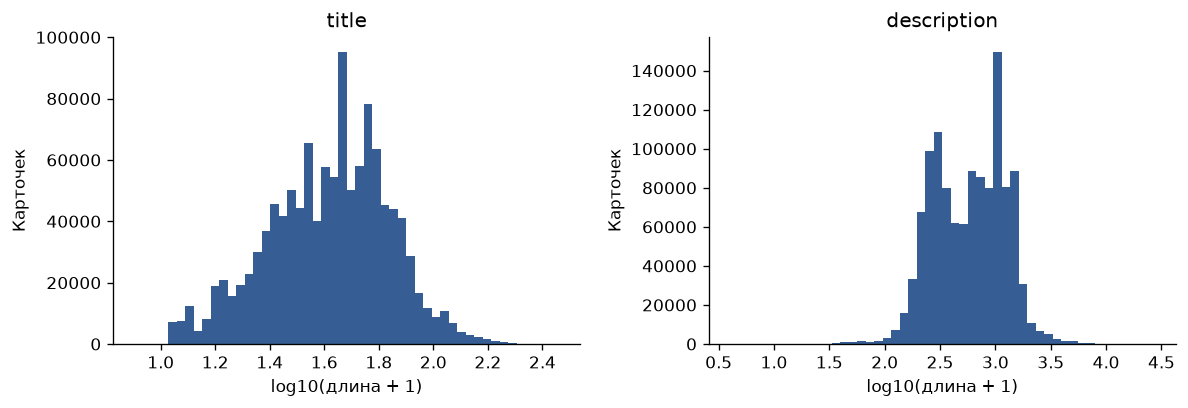

In [2]:
quality = text_quality(RAW)
display(pd.DataFrame(quality["quality"]).round(2))
display(
    pd.DataFrame(
        {name: row["p50_p90_p99"] for name, row in quality["lengths"].items()},
        index=["p50", "p90", "p99"],
    )
)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for axis, (name, values) in zip(axes, quality["lengths"].items(), strict=True):
    axis.stairs(values["histogram"], values["bins"], fill=True, color="#365e94")
    axis.set(title=name, xlabel="log10(длина + 1)", ylabel="Карточек")
fig.tight_layout()
fig.savefig(FIGURES / "text-length.png", bbox_inches="tight")
display(fig)
plt.close(fig)

# Концентрация кликов

Используется агрегат кликов, заново рассчитанный из исходного query_clicks.
Сильная концентрация означает, что качество по трафику и по карточкам нужно
показывать отдельно. Взвешенная метрика сама по себе не оценивает весь хвост.

,доля SKU,доля кликов
0,1.0,37.52
1,10.0,81.25
2,50.0,98.70
3,100.0,100.00


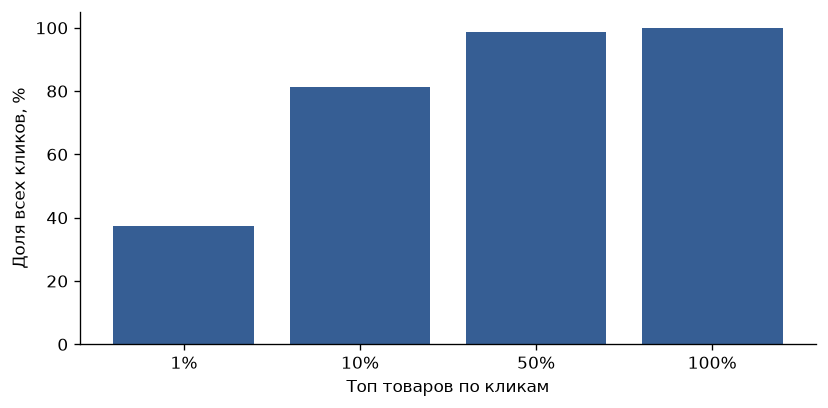

In [3]:
clicks = traffic(PROCESSED)
display(pd.DataFrame(clicks["concentration"]).mul(100).round(2))
fig, axis = plt.subplots(figsize=(7, 3.5))
axis.bar(
    [f"{r['доля SKU']:.0%}" for r in clicks["concentration"]],
    [100 * r["доля кликов"] for r in clicks["concentration"]],
    color="#365e94",
)
axis.set(xlabel="Топ товаров по кликам", ylabel="Доля всех кликов, %", ylim=(0, 105))
fig.tight_layout()
fig.savefig(FIGURES / "click-concentration.png", bbox_inches="tight")
display(fig)
plt.close(fig)

# Пересечения и разбиение

Gold — параметры `_search` и каталожные бренд/модель. Они хранятся отдельно
от входных параметров продавца. Это принятая интерпретация данных, не ручная
семантическая разметка. Новые категории целиком исключаются из train.
Обязательные поля и веса выводятся из каталога и трафика по явно заданной
эвристике; их построение не заявляется независимым от test.

In [4]:
stats = json.loads((PROCESSED / "stats.json").read_text())
display(pd.DataFrame(stats["skus"].items(), columns=["пересечение", "SKU"]))
display(pd.DataFrame(stats["splits"].items(), columns=["split", "SKU"]))
display(
    pd.DataFrame(
        stats["categories"]["new_category_paths"], columns=["отложенная категория"]
    )
)
print("Категорий с обязательными полями:", stats["categories"]["eligible"])
print("Обязательных полей в схемах:", stats["required_rows"])

,пересечение,SKU
0,sku_desc,1177200
1,catalog_offers,546069
2,catalog_offers_with_category,546069
3,query_clicks_unique,332753
4,offers_and_desc,241355
5,offers_and_clicks,241661
6,desc_and_clicks,158158
7,all_three,102945
8,gold_skus,546069
9,gold_skus_with_desc,241355


,split,SKU
0,val,54508
1,train,433672
2,new_category,4002
3,test,53887


,отложенная категория
0,Товары для бритья и стрижки / Электробритвы / ...
1,Холодильники и морозильники / Холодильники и м...
2,Товары для ухода за одеждой / Швейные машины /...
3,Товары для укладки волос / Выпрямители волос /...
4,Аксессуары для телефонов / Пленки и стекла для...
5,Компьютерные комплектующие / Оперативная памят...
6,Силовая техника и строительное оборудование / ...
7,Строительные расходные материалы и оснастка / ...


Категорий с обязательными полями: 1107
Обязательных полей в схемах: 8297


# Значение эталона во входном тексте

Детерминированная выборка до 20 тысяч train-карточек с текстом. Проверяется
буквальное присутствие значения после очистки HTML, регистра и пробелов.
Это диагностический показатель: эквивалентные единицы, синонимы и подстроки
требуют отдельной оценки. Его нельзя считать семантическим потолком recall.
Также сравниваются одноимённые поля продавца и gold; диапазон продавца
не приравнивается к точному значению эталона.

,атрибут,пар,"в тексте, %","без блока, %"
0,Бренд,19238,98.39,98.39
1,Модель,19238,96.55,96.55
2,Цвет,7004,26.00,25.69
3,Высота,5269,69.67,69.42
4,Серия,4230,67.68,67.66
5,Ширина,3880,72.81,72.68
6,Вес,3840,3.26,3.26
7,Тип,2367,4.14,4.14
8,Вид выпуска товара,2353,0.00,0.00
9,"Вид занавески, штор",2251,0.00,0.00


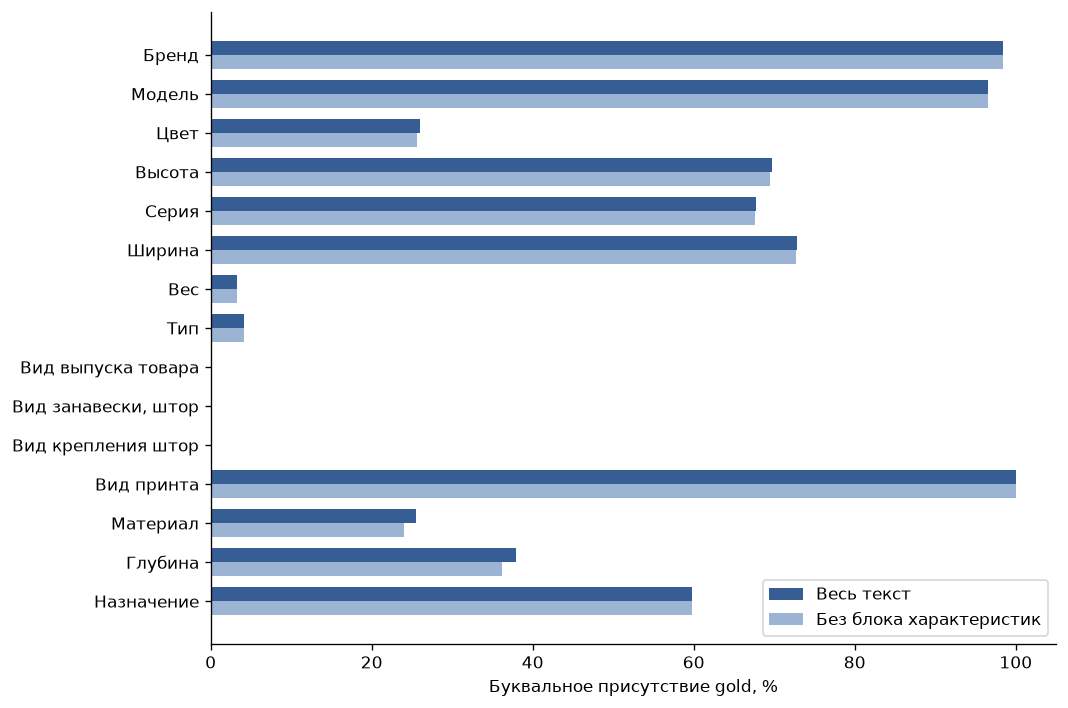

In [5]:
evidence = grounding(PROCESSED)
display(pd.DataFrame(evidence["attributes"]).head(20).round(2))
top = pd.DataFrame(evidence["attributes"]).head(15).iloc[::-1]
fig, axis = plt.subplots(figsize=(9, 6))
positions = np.arange(len(top))
axis.barh(
    positions + 0.18,
    top["в тексте, %"],
    height=0.36,
    color="#365e94",
    label="Весь текст",
)
axis.barh(
    positions - 0.18,
    top["без блока, %"],
    height=0.36,
    color="#9cb4d3",
    label="Без блока характеристик",
)
axis.set_yticks(positions, top["атрибут"])
axis.set(xlabel="Буквальное присутствие gold, %", xlim=(0, 105))
axis.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "gold-overlap.png", bbox_inches="tight")
display(fig)
plt.close(fig)

# Выводы для реализации

HTML очищается до извлечения; проверка наличия цитаты выполняется отдельно
от семантического соответствия значения. Метрики показываются по категориям
и атрибутам, а также с весами трафика. Нормализация единиц и значений нужна
до сравнения с каталогом. Отсутствующие в тексте сведения остаются пропусками.
EDA не измеряет качество извлечения. Включённый набор предсказаний проверяет исполнение; для оценки точности нужен отдельный размеченный набор.

In [6]:
summary = {
    "created_at": datetime.now(UTC).isoformat(),
    "dataset_version": manifest["version"],
    "inputs": input_table(RAW),
    "quality": quality,
    "traffic": clicks,
    "grounding": evidence,
    "splits": stats["splits"],
}
REPORT.write_text(json.dumps(summary, ensure_ascii=False, indent=2) + "\n")
print("Train-карточек в выборке:", evidence["sample_size"])
print("Пар с gold:", evidence["required_gold_pairs"])
print(f"Буквальное присутствие: {evidence['literal_overlap']:.2%}")
print(f"Без блока характеристик: {evidence['literal_overlap_without_spec']:.2%}")
if evidence["seller_literal_match"] is not None:
    print(f"Совпадение полей продавца и gold: {evidence['seller_literal_match']:.2%}")
else:
    print("В выборке нет одноимённых полей продавца и gold для сравнения.")

Train-карточек в выборке: 20000
Пар с gold: 122971
Буквальное присутствие: 58.41%
Без блока характеристик: 58.06%
Совпадение полей продавца и gold: 58.93%
